In [104]:
#THis code is to check if the video is corrupted or not..
#If the video is corrupted delete the video.
import glob
import torch
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader
from torch.utils.data.dataset import Dataset
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
#Check if the file is corrupted or not
def validate_video(vid_path,train_transforms):
      transform = train_transforms
      count = 20
      video_path = vid_path
      frames = []
      a = int(100/count)
      first_frame = np.random.randint(0,a)
      temp_video = video_path.split('/')[-1]
      for i,frame in enumerate(frame_extract(video_path)):
        frames.append(transform(frame))
        if(len(frames) == count):
          break
      frames = torch.stack(frames)
      frames = frames[:count]
      return frames
#extract a from from video
def frame_extract(path):
  vidObj = cv2.VideoCapture(path) 
  success = 1
  while success:
      success, image = vidObj.read()
      if success:
          yield image

im_size = 112
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transforms = transforms.Compose([
                                        transforms.ToPILImage(),
                                        transforms.Resize((im_size,im_size)),
                                        transforms.ToTensor(),
                                        transforms.Normalize(mean,std)])
video_fil_real =  glob.glob('./real_yt_face_videos/*.mp4')
video_fil_fake = glob.glob('./fake_yt_face_videos/*.mp4')
# video_fil += glob.glob('/content/drive/My Drive/DFDC_FAKE_Face_only_data/*.mp4')
# video_fil += glob.glob('/content/drive/My Drive/DFDC_REAL_Face_only_data/*.mp4')
# video_fil += glob.glob('/content/drive/My Drive/FF_Face_only_data/*.mp4')
print("Total no of real videos :" , len(video_fil_real))
print("Total no of fake videos :" , len(video_fil_fake))
print(video_fil_real)
count_real = 0
for i in video_fil_real:
  try:
    count_real+=1
    validate_video(i,train_transforms)
  except:
    print("Number of real video processed: " , count_real ," Remaining : " , (len(video_fil_real) - count_real))
    print("Corrupted real video is : " , i)
    continue
print((len(video_fil_real) - count_real))

count_fake = 0
for i in video_fil_fake:
  try:
    count_fake+=1
    validate_video(i,train_transforms)
  except:
    print("Number of fake video processed: " , count_fake ," Remaining : " , (len(video_fil_fake) - count_fake))
    print("Corrupted fake video is : " , i)
    continue
print((len(video_fil_fake) - count_fake))

Total no of real videos : 1000
Total no of fake videos : 1000
['./real_yt_face_videos/578.mp4', './real_yt_face_videos/544.mp4', './real_yt_face_videos/222.mp4', './real_yt_face_videos/236.mp4', './real_yt_face_videos/550.mp4', './real_yt_face_videos/587.mp4', './real_yt_face_videos/593.mp4', './real_yt_face_videos/008.mp4', './real_yt_face_videos/020.mp4', './real_yt_face_videos/746.mp4', './real_yt_face_videos/752.mp4', './real_yt_face_videos/034.mp4', './real_yt_face_videos/961.mp4', './real_yt_face_videos/975.mp4', './real_yt_face_videos/785.mp4', './real_yt_face_videos/791.mp4', './real_yt_face_videos/949.mp4', './real_yt_face_videos/168.mp4', './real_yt_face_videos/154.mp4', './real_yt_face_videos/632.mp4', './real_yt_face_videos/626.mp4', './real_yt_face_videos/140.mp4', './real_yt_face_videos/815.mp4', './real_yt_face_videos/801.mp4', './real_yt_face_videos/197.mp4', './real_yt_face_videos/829.mp4', './real_yt_face_videos/183.mp4', './real_yt_face_videos/418.mp4', './real_yt_fa

In [ ]:
#Frame-count statistics for the face-cropped videos
import glob
import numpy as np
import cv2

video_files_real = []
frame_count = []
for video_file in glob.glob('./real_yt_face_videos/*.mp4'):
    cap = cv2.VideoCapture(video_file)
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.release()
    if n < 100:
        continue
    video_files_real.append(video_file)
    frame_count.append(n)
print("frames:", frame_count)
print("Total number of videos:", len(frame_count))
print("Average frames per video:", np.mean(frame_count))

video_files_fake = []
frame_count = []
for video_file in glob.glob('./fake_yt_face_videos/*.mp4'):
    cap = cv2.VideoCapture(video_file)
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.release()
    if n < 100:
        continue
    video_files_fake.append(video_file)
    frame_count.append(n)
print("frames:", frame_count)
print("Total number of videos:", len(frame_count))
print("Average frames per video:", np.mean(frame_count))


Train: 1600 videos (800 real, 800 fake)
Val: 400 videos (200 real, 200 fake)
Sample label: REAL


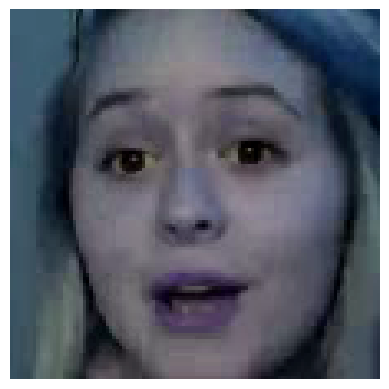

In [11]:
import os
import random
import torch
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader, Dataset
import numpy as np
import cv2
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Configuration
real_videos_folder = './real_yt_face_videos'
fake_videos_folder = './fake_yt_face_videos'
im_size = 112
sequence_length = 10
batch_size = 4

# 1. Load and label videos
def load_video_paths(real_dir, fake_dir):
    real_videos = [os.path.join(real_dir, f) for f in os.listdir(real_dir) 
                  if f.endswith(('.mp4', '.avi', '.mov'))]
    fake_videos = [os.path.join(fake_dir, f) for f in os.listdir(fake_dir)
                  if f.endswith(('.mp4', '.avi', '.mov'))]
    
    # Create labels (1=real, 0=fake)
    video_paths = real_videos + fake_videos
    labels = [1]*len(real_videos) + [0]*len(fake_videos)
    
    # Shuffle together
    combined = list(zip(video_paths, labels))
    random.shuffle(combined)
    video_paths, labels = zip(*combined)
    
    return video_paths, labels

# 2. Modified Dataset Class
class VideoDataset(Dataset):
    def __init__(self, video_paths, labels, sequence_length=60, transform=None):
        self.video_paths = video_paths
        self.labels = labels
        self.transform = transform
        self.seq_length = sequence_length
        
    def __len__(self):
        return len(self.video_paths)
    
    def __getitem__(self, idx):
        video_path = self.video_paths[idx]
        label = self.labels[idx]
        
        frames = []
        for i, frame in enumerate(self.frame_extract(video_path)):
            if self.transform:
                frame = self.transform(frame)
            frames.append(frame)
            if len(frames) == self.seq_length:
                break
                
        # Pad if video is shorter than sequence length
        while len(frames) < self.seq_length:
            frames.append(frames[-1])
            
        return torch.stack(frames), torch.tensor(label, dtype=torch.long)
    
    def frame_extract(self, path):
        cap = cv2.VideoCapture(path)
        while cap.isOpened():
            ret, frame = cap.read()
            if not ret:
                break
            yield frame
        cap.release()

# 3. Data Preparation Pipeline
# Load and split data
video_paths, labels = load_video_paths(real_videos_folder, fake_videos_folder)
train_paths, val_paths, train_labels, val_labels = train_test_split(
    video_paths, labels, test_size=0.2, stratify=labels, random_state=42
)

# Print dataset stats
print(f"Train: {len(train_paths)} videos ({sum(train_labels)} real, {len(train_labels)-sum(train_labels)} fake)")
print(f"Val: {len(val_paths)} videos ({sum(val_labels)} real, {len(val_labels)-sum(val_labels)} fake)")

# Transforms
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transforms = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((im_size, im_size)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

val_transforms = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((im_size, im_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Create datasets and dataloaders
train_dataset = VideoDataset(train_paths, train_labels, sequence_length, train_transforms)
val_dataset = VideoDataset(val_paths, val_labels, sequence_length, val_transforms)

train_loader = DataLoader(train_dataset, batch_size=batch_size, 
                         shuffle=True, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size,
                       shuffle=False, num_workers=0, pin_memory=True)

# Visualization function
def im_plot(tensor):
    image = tensor.cpu().numpy().transpose(1, 2, 0)
    image = image * std + mean  # Unnormalize
    image = np.clip(image, 0, 1)
    plt.imshow(image)
    plt.axis('off')
    plt.show()

# Test visualization
sample_frames, sample_label = train_dataset[4]
print(f"Sample label: {'REAL' if sample_label == 1 else 'FAKE'}")
im_plot(sample_frames[0])  # Show first frame

MODEL

In [ ]:
#Model with feature visualization
from torch import nn
from torchvision import models
class Model(nn.Module):
    def __init__(self, num_classes,latent_dim= 2048, lstm_layers=1 , hidden_dim = 2048, bidirectional = False):
        super(Model, self).__init__()
        model = models.resnext50_32x4d(weights=models.ResNeXt50_32X4D_Weights.IMAGENET1K_V1) #Residual Network CNN
        self.model = nn.Sequential(*list(model.children())[:-2])
        self.lstm = nn.LSTM(latent_dim,hidden_dim, lstm_layers,  bidirectional)  # NB: 4th positional arg is `bias`; kept as-is so saved checkpoints still load
        self.relu = nn.LeakyReLU()
        self.dp = nn.Dropout(0.4)
        self.linear1 = nn.Linear(2048,num_classes)
        self.avgpool = nn.AdaptiveAvgPool2d(1)
    def forward(self, x):
        batch_size,seq_length, c, h, w = x.shape
        x = x.view(batch_size * seq_length, c, h, w)
        fmap = self.model(x)
        x = self.avgpool(fmap)
        x = x.view(batch_size,seq_length,2048)
        x_lstm,_ = self.lstm(x,None)
        return fmap,self.dp(self.linear1(torch.mean(x_lstm,dim = 1)))

In [92]:
import torch
from torch import nn
from torchvision import models

# Squeeze-and-Excitation Block
class SEBlock(nn.Module):
    def __init__(self, in_channels, reduction=16):
        super(SEBlock, self).__init__()
        self.se = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(in_channels, in_channels // reduction, 1),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_channels // reduction, in_channels, 1),
            nn.Sigmoid()
        )
    
    def forward(self, x):
        scale = self.se(x)
        return x * scale

# Spatial Attention Block
class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super(SpatialAttention, self).__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size, padding=kernel_size // 2, bias=False)
        self.sigmoid = nn.Sigmoid()
    
    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        attn = torch.cat([avg_out, max_out], dim=1)
        attn = self.conv(attn)
        return x * self.sigmoid(attn)

class EnhancedModel(nn.Module):
    def __init__(self, num_classes, latent_dim=2048, lstm_layers=1, hidden_dim=2048, bidirectional=False):
        super(EnhancedModel, self).__init__()

        # Feature extractor
        base_model = models.resnext50_32x4d(weights=models.ResNeXt50_32X4D_Weights.IMAGENET1K_V1)
        self.feature_extractor = nn.Sequential(*list(base_model.children())[:-2])
        
        # SE block + Spatial attention
        self.se = SEBlock(2048)
        self.spatial_attn = SpatialAttention()
        self.avgpool = nn.AdaptiveAvgPool2d(1)

        # LSTM
        self.lstm = nn.LSTM(latent_dim, hidden_dim, lstm_layers, batch_first=True, bidirectional=bidirectional)
        lstm_output_dim = hidden_dim * (2 if bidirectional else 1)
        self.norm = nn.LayerNorm(lstm_output_dim)

        # Classifier with residual connection
        self.fc1 = nn.Linear(lstm_output_dim, lstm_output_dim)
        self.act = nn.GELU()
        self.dp = nn.Dropout(0.4)
        self.fc2 = nn.Linear(lstm_output_dim, num_classes)

    def forward(self, x):
        batch_size, seq_len, c, h, w = x.shape

        # CNN feature extraction
        x = x.view(batch_size * seq_len, c, h, w)
        fmap = self.feature_extractor(x)                     # (B*T, 2048, H', W')
        x = self.se(fmap)
        x = self.spatial_attn(x)
        x = self.avgpool(x)
        x = x.view(batch_size, seq_len, -1)                  # (B, T, 2048)

        # LSTM
        x_lstm, _ = self.lstm(x)                             # (B, T, H)
        x_lstm = self.norm(x_lstm)

        # Temporal aggregation
        x_mean = x_lstm.mean(dim=1)

        # Residual classifier
        residual = x_mean
        x_out = self.fc1(x_mean)
        x_out = self.act(x_out)
        x_out = self.dp(x_out)
        x_out = x_out + residual                             # Residual connection
        logits = self.fc2(x_out)

        return fmap, logits


Instantiate the model and run a dummy forward pass as a sanity check.


In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available()
                      else "cpu")
print(f"Using device: {device}")

model = EnhancedModel(2).to(device)

with torch.no_grad():
    fmap, logits = model(torch.zeros(1, 20, 3, 112, 112, device=device))
print(fmap.shape, logits.shape)


In [90]:
import seaborn as sn
from sklearn.metrics import confusion_matrix
import pandas as pd
#Output confusion matrix
def print_confusion_matrix(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    print('True positive = ', cm[0][0])
    print('False positive = ', cm[0][1])
    print('False negative = ', cm[1][0])
    print('True negative = ', cm[1][1])
    print('\n')
    df_cm = pd.DataFrame(cm, range(2), range(2))
    sn.set(font_scale=1.4) # for label size
    sn.heatmap(df_cm, annot=True, annot_kws={"size": 16}) # font size
    plt.ylabel('Actual label', size = 20)
    plt.xlabel('Predicted label', size = 20)
    plt.xticks(np.arange(2), ['Fake', 'Real'], size = 16)
    plt.yticks(np.arange(2), ['Fake', 'Real'], size = 16)
    plt.ylim([2, 0])
    plt.show()
    calculated_acc = (cm[0][0]+cm[1][1])/(cm[0][0]+cm[0][1]+cm[1][0]+ cm[1][1])
    print("Calculated Accuracy",calculated_acc*100)

In [74]:
def plot_loss(train_loss_avg,test_loss_avg,num_epochs):
  loss_train = train_loss_avg
  loss_val = test_loss_avg
  print(num_epochs)
  epochs = range(1,num_epochs+1)
  plt.plot(epochs, loss_train, 'g', label='Training loss')
  plt.plot(epochs, loss_val, 'b', label='validation loss')
  plt.title('Training and Validation loss')
  plt.xlabel('Epochs')
  plt.ylabel('Loss')
  plt.legend()
  plt.show()
def plot_accuracy(train_accuracy,test_accuracy,num_epochs):
  loss_train = train_accuracy
  loss_val = test_accuracy
  epochs = range(1,num_epochs+1)
  plt.plot(epochs, loss_train, 'g', label='Training accuracy')
  plt.plot(epochs, loss_val, 'b', label='validation accuracy')
  plt.title('Training and Validation accuracy')
  plt.xlabel('Epochs')
  plt.ylabel('Accuracy')
  plt.legend()
  plt.show()

Training / evaluation helpers. `train_epoch` saves the weights to `./checkpoint.pt` after every epoch.


In [ ]:
import torch
from torch.autograd import Variable
import time
import os
import sys

# Set device
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

def train_epoch(epoch, num_epochs, data_loader, model, criterion, optimizer):
    model.train()
    losses = AverageMeter()
    accuracies = AverageMeter()
    for i, (inputs, targets) in enumerate(data_loader):
        inputs = inputs.to(device)
        targets = targets.to(device).long()

        _, outputs = model(inputs)
        loss = criterion(outputs, targets)
        acc = calculate_accuracy(outputs, targets)

        losses.update(loss.item(), inputs.size(0))
        accuracies.update(acc, inputs.size(0))

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        sys.stdout.write(
            "\r[Epoch %d/%d] [Batch %d / %d] [Loss: %f, Acc: %.2f%%]"
            % (
                epoch,
                num_epochs,
                i,
                len(data_loader),
                losses.avg,
                accuracies.avg
            )
        )
    torch.save(model.state_dict(), './checkpoint.pt')
    return losses.avg, accuracies.avg

def test(epoch, model, data_loader, criterion):
    print('Testing')
    model.eval()
    losses = AverageMeter()
    accuracies = AverageMeter()
    pred = []
    true = []

    with torch.no_grad():
        for i, (inputs, targets) in enumerate(data_loader):
            inputs = inputs.to(device)
            targets = targets.to(device).long()

            _, outputs = model(inputs)
            loss = criterion(outputs, targets)
            acc = calculate_accuracy(outputs, targets)

            _, p = torch.max(outputs, 1)

            true += targets.cpu().numpy().reshape(len(targets)).tolist()
            pred += p.cpu().numpy().reshape(len(p)).tolist()

            losses.update(loss.item(), inputs.size(0))
            accuracies.update(acc, inputs.size(0))

            sys.stdout.write(
                "\r[Batch %d / %d]  [Loss: %f, Acc: %.2f%%]"
                % (
                    i,
                    len(data_loader),
                    losses.avg,
                    accuracies.avg
                )
            )
        print('\nAccuracy {}'.format(accuracies.avg))
    return true, pred, losses.avg, accuracies.avg

class AverageMeter(object):
    """Computes and stores the average and current value"""
    def __init__(self):
        self.reset()
    def reset(self):
        self.val = 0
        self.avg = 0
        self.sum = 0
        self.count = 0
    def update(self, val, n=1):
        self.val = val
        self.sum += val * n
        self.count += n
        self.avg = self.sum / self.count

def calculate_accuracy(outputs, targets):
    batch_size = targets.size(0)
    _, pred = outputs.topk(1, 1, True)
    pred = pred.t()
    correct = pred.eq(targets.view(1, -1))
    n_correct_elems = correct.float().sum().item()
    return 100 * n_correct_elems / batch_size


In [94]:
#learning rate
lr = 1e-5#0.001
#number of epochs 
num_epochs = 20

optimizer = torch.optim.Adam(model.parameters(), lr= lr,weight_decay = 1e-5)

#class_weights = torch.from_numpy(np.asarray([1,15])).type(torch.FloatTensor).cuda()
#criterion = nn.CrossEntropyLoss(weight = class_weights).cuda()
criterion = nn.CrossEntropyLoss().to(device)
train_loss_avg =[]
train_accuracy = []
test_loss_avg = []
test_accuracy = []
for epoch in range(1,num_epochs+1):
    l, acc = train_epoch(epoch,num_epochs,train_loader,model,criterion,optimizer)
    train_loss_avg.append(l)
    train_accuracy.append(acc)
    true,pred,tl,t_acc = test(epoch,model,val_loader,criterion)
    test_loss_avg.append(tl)
    test_accuracy.append(t_acc)
plot_loss(train_loss_avg,test_loss_avg,len(train_loss_avg))
plot_accuracy(train_accuracy,test_accuracy,len(train_accuracy))
print(confusion_matrix(true,pred))
print_confusion_matrix(true,pred)

[Epoch 1/20] [Batch 399 / 400] [Loss: 0.676322, Acc: 61.12%]Testing
[Batch 99 / 100]  [Loss: 0.535485, Acc: 73.25%]
Accuracy 73.25
[Epoch 2/20] [Batch 399 / 400] [Loss: 0.573353, Acc: 70.69%]Testing
[Batch 99 / 100]  [Loss: 0.501390, Acc: 74.25%]
Accuracy 74.25
[Epoch 3/20] [Batch 399 / 400] [Loss: 0.477410, Acc: 77.75%]Testing
[Batch 99 / 100]  [Loss: 0.495102, Acc: 76.00%]
Accuracy 76.0
[Epoch 4/20] [Batch 399 / 400] [Loss: 0.359293, Acc: 83.25%]Testing
[Batch 99 / 100]  [Loss: 0.553029, Acc: 75.25%]
Accuracy 75.25
[Epoch 5/20] [Batch 399 / 400] [Loss: 0.320453, Acc: 86.50%]Testing
[Batch 99 / 100]  [Loss: 0.541788, Acc: 73.50%]
Accuracy 73.5
[Epoch 6/20] [Batch 7 / 400] [Loss: 0.332576, Acc: 84.38%]]

KeyboardInterrupt: 

## Load a saved checkpoint


In [ ]:
# Optional: load trained weights instead of training from scratch
import torch

device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available()
                      else "cpu")
print(f"Using device: {device}")

model = EnhancedModel(2).to(device)
path_to_model = './final_model/checkpoint1.pt'
model.load_state_dict(torch.load(path_to_model, map_location=device))


5


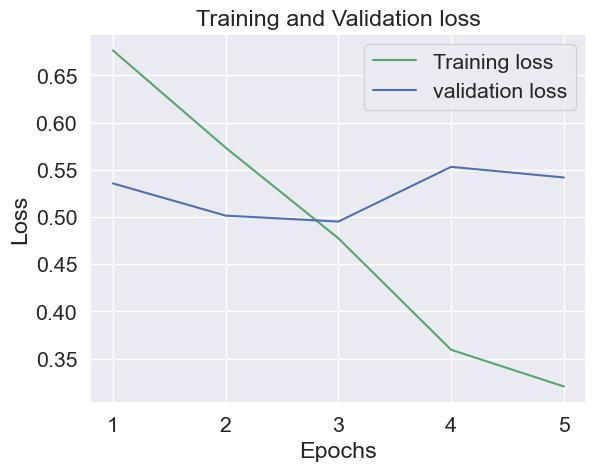

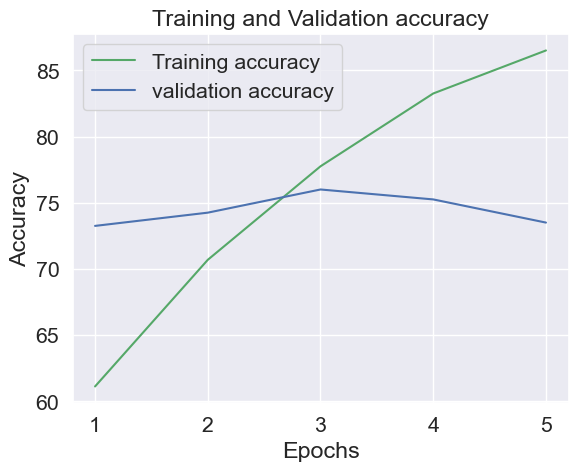

[[129  71]
 [ 35 165]]
True positive =  129
False positive =  71
False negative =  35
True negative =  165




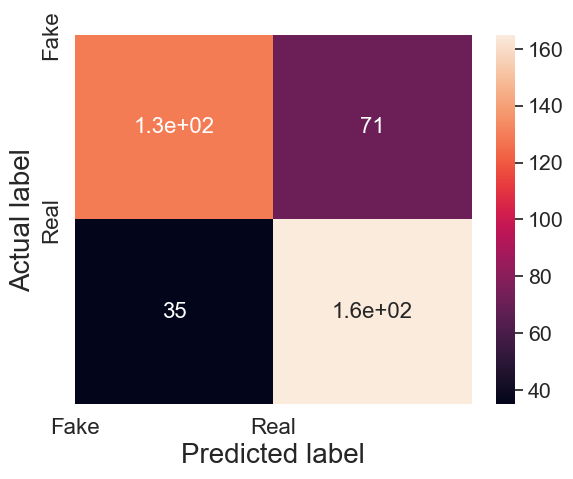

Calculated Accuracy 73.5


In [103]:
plot_loss(train_loss_avg,test_loss_avg,len(train_loss_avg))
plot_accuracy(train_accuracy,test_accuracy,len(train_accuracy))
print(confusion_matrix(true,pred))
print_confusion_matrix(true,pred)